# 01 · Comprensión de los datos y calidad

Describir el dataset, verificar su calidad y documentar las decisiones de limpieza 1 a 5.

## Preparación

In [1]:
from pathlib import Path
import sys

# Busca la raíz del repo (la carpeta que contiene src/) sin importar desde dónde se abra el notebook.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")  # estilo común para todas las figuras del proyecto

from src import contratos, rutas
from src import carga, limpieza

## 1. Comprensión de los datos

- **Procedencia y licencia:**  MovieLens `ml-latest-small`, publicado por GroupLens (Universidad de Minnesota) y generado el 26 de septiembre de 2018 (<https://grouplens.org/datasets/movielens/latest/>). Se puede usar para investigación sin fines comerciales, sin implicar respaldo de la universidad; se puede redistribuir (incluidas transformaciones) bajo las mismas condiciones y hay que citar a Harper & Konstan (2015). La cita y la licencia están en el `README.md`.
- **Contexto en que se generaron los datos:** Son calificaciones hechas en [MovieLens](https://movielens.org), un servicio de recomendación de películas operado por GroupLens. 610 usuarios fueron elegidos al azar entre quienes habían calificado al menos 20 películas; sus ratings van de marzo de 1996 a septiembre de 2018. No hay datos demográficos: cada usuario es solo un id. Es un conjunto de *desarrollo*, no de referencia.
- **Variables de cada tabla y unidad de observación:** 
   - `ratings`: `userId`, `movieId`, `rating` (de 0.5 a 5.0 en pasos de 0.5) y `timestamp` (segundos desde 1970 en UTC). **Una fila es una calificación** (usuario × película).
   - `movies`: `movieId`, `title` (con el año de estreno entre paréntesis) y `genres` (géneros separados por `|`). **Una fila es una película.**

- **Por qué no usamos `links` y `tags`:** `links` solo enlaza los ids con IMDb y TMDb, y no aporta variables para nuestras preguntas. `tags` es texto libre de los usuarios, y limpiarlo requiere un trabajo que no cabe en el plazo; además solo tiene 3,683 etiquetas frente a 100,836 ratings.
- **Preguntas de investigación y por qué estos datos sirven para responderlas:** (1) ¿las películas con más calificaciones generan opiniones más divididas?, y (2) si a un usuario le gusta una película o un género (rating ≥ 4), ¿qué otras tienden a gustarle? Ambas se contestan con `ratings` (quién calificó qué y cuánto) y `movies` (título, año y géneros). Hay una limitación: los usuarios son una muestra autoseleccionada, así que no representan al público general.

## 2. Carga con tipos 

In [2]:
movies_raw = carga.cargar_movies()
ratings_raw = carga.cargar_ratings()
contratos.verificar_esquema(movies_raw, "movies_raw")
contratos.verificar_esquema(ratings_raw, "ratings_raw")

print(f"movies:  {movies_raw.shape[0]:,} filas x {movies_raw.shape[1]} columnas")
print(f"ratings: {ratings_raw.shape[0]:,} filas x {ratings_raw.shape[1]} columnas")
print(f"Usuarios distintos:  {ratings_raw['userId'].nunique():,}")
print(f"Películas distintas en movies: {movies_raw['movieId'].nunique():,}")

movies:  9,742 filas x 3 columnas
ratings: 100,836 filas x 4 columnas
Usuarios distintos:  610
Películas distintas en movies: 9,742


In [3]:
movies_raw.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
ratings_raw.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [5]:
print("Tipos de dato de movies:")
print(movies_raw.dtypes)
print("\nTipos de dato de ratings:")
print(ratings_raw.dtypes)

Tipos de dato de movies:
movieId    object
title      object
genres     object
dtype: object

Tipos de dato de ratings:
userId        object
movieId       object
rating       float64
timestamp      int64
dtype: object


**Evidencia de la decisión 1.** Los identificadores (IDs) se utilizan para identificar registros, no para realizar operaciones matemáticas. Por ello, es importante conservarlos en un formato adecuado. Si Pandas los interpreta como valores numéricos y existen datos faltantes, puede convertirlos a tipo decimal, mostrando valores como `1.0` en lugar de `1`. A continuación, se compara la lectura predeterminada de Pandas con la configuración utilizada para evitar este problema.

In [6]:
# Riesgo: un solo vacío convierte los ids enteros en reales
ids_con_vacio = pd.Series([1, 2, None])
print("Ids con un vacío, convertidos a texto:", ids_con_vacio.astype(str).tolist())

# Lectura por defecto (pandas adivina el tipo) frente a nuestra lectura (texto)
por_defecto = pd.read_csv(rutas.DATOS / "ratings.csv")
tipos = pd.DataFrame({
    "por defecto": por_defecto[["userId", "movieId"]].dtypes.astype(str),
    "nuestra lectura": ratings_raw[["userId", "movieId"]].dtypes.astype(str),
})
tipos

Ids con un vacío, convertidos a texto: ['1.0', '2.0', 'nan']


,por defecto,nuestra lectura
userId,int64,object
movieId,int64,object


## 3. Validaciones



### 3.1 Valores Vacíos

In [7]:
# Valores vacíos en ambas tablas
nulos_movies = movies_raw.isna().sum()
nulos_ratings = ratings_raw.isna().sum()

print("Valores vacíos en movies:")
print(nulos_movies)
print("\nValores vacíos en ratings:")
print(nulos_ratings)
print(f"\nTotal de vacíos: movies = {nulos_movies.sum()}, ratings = {nulos_ratings.sum()}")

Valores vacíos en movies:
movieId    0
title      0
genres     0
dtype: int64

Valores vacíos en ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Total de vacíos: movies = 0, ratings = 0


### 3.2 llaves
Una **llave** es la columna (o combinación de columnas) que identifica cada fila de forma única. Se espera que `movieId` sea llave de `movies` y que `(userId, movieId)` sea llave de `ratings` (un usuario califica una película una sola vez).

In [8]:
# llaves con limpieza.validar_llave: movieId en movies; (userId, movieId) en ratings
print('movieId en movies:', limpieza.validar_llave(movies_raw, ['movieId']))
print('(userId, movieId) en ratings:', limpieza.validar_llave(ratings_raw, ['userId', 'movieId']))

movieId en movies: {'es_llave': True, 'duplicados': 0, 'nulos': 0}
(userId, movieId) en ratings: {'es_llave': True, 'duplicados': 0, 'nulos': 0}


### 3.3 Integridad entre tablas


In [9]:
# integridad entre tablas: ratings de películas inexistentes; películas sin ratings
ids_movies = set(movies_raw["movieId"])
ids_ratings = set(ratings_raw["movieId"])

ratings_huerfanos = ratings_raw[~ratings_raw["movieId"].isin(ids_movies)]
peliculas_sin_rating = movies_raw[~movies_raw["movieId"].isin(ids_ratings)]

print(f"Ratings de películas que no existen en movies: {len(ratings_huerfanos)}")
print(f"Películas sin ningún rating: {len(peliculas_sin_rating)}")
peliculas_sin_rating.head()

Ratings de películas que no existen en movies: 0
Películas sin ningún rating: 18


,movieId,title,genres
816,1076,"Innocents, The (1961)",Drama|Horror|Thriller
2211,2939,Niagara (1953),Drama|Thriller
2499,3338,For All Mankind (1989),Documentary
2587,3456,"Color of Paradise, The (Rang-e khoda) (1999)",Drama
3118,4194,I Know Where I'm Going! (1945),Drama|Romance|War


### 3.4 Valores de `rating`

In [10]:
# rating dentro de {0.5, ..., 5.0}
valores_rating = [float(v) for v in sorted(ratings_raw['rating'].unique())]
print('Valores distintos de rating:', valores_rating)
print('¿Todos dentro de {0.5, 1.0, ..., 5.0}?', set(valores_rating) <= set(limpieza.RATINGS_VALIDOS))

print('Número de ratings por valor:')
ratings_raw['rating'].value_counts().sort_index()

Valores distintos de rating: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
¿Todos dentro de {0.5, 1.0, ..., 5.0}? True
Número de ratings por valor:


rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

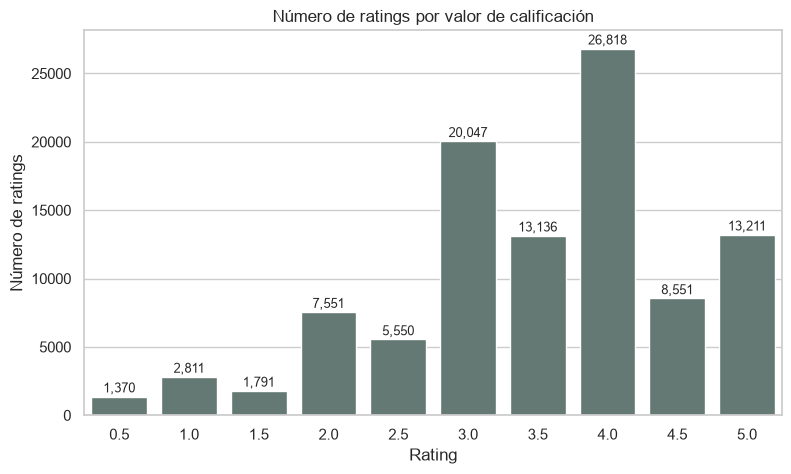

In [11]:
conteo = ratings_raw["rating"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=conteo.index, y=conteo.values, color="#607D75", ax=ax)
for i, v in enumerate(conteo.values):
    ax.text(i, v + 300, f"{v:,}", ha="center", fontsize=9)
ax.set(title="Número de ratings por valor de calificación",
       xlabel="Rating", ylabel="Número de ratings")
plt.show()


### 3.5 Rango de fecha

In [12]:
# rango de fechas (después de convertir timestamp)
fechas = pd.to_datetime(ratings_raw['timestamp'], unit='s', utc=True)
print('Primer rating:', fechas.min())
print('Último rating:', fechas.max())

Primer rating: 1996-03-29 18:36:55+00:00
Último rating: 2018-09-24 14:27:30+00:00


## 4. Géneros (decisiones 3 y 4)

In [13]:
#géneros únicos después de separar por '|'; comparar con la lista del README (IMAX, Children's)
generos_readme = [
    "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime", "Documentary",
    "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery", "Romance",
    "Sci-Fi", "Thriller", "War", "Western", "(no genres listed)",
]
peliculas_por_genero = movies_raw['genres'].str.split('|').explode().value_counts()

print(f'Géneros distintos en los datos: {len(peliculas_por_genero)}')
print('En los datos pero NO en el README:', sorted(set(peliculas_por_genero.index) - set(generos_readme)))
print('En el README pero NO en los datos:', sorted(set(generos_readme) - set(peliculas_por_genero.index)))

print('='*50)
print('Películas por género (una película puede tener varios):')
print('='*50)
peliculas_por_genero

Géneros distintos en los datos: 20
En los datos pero NO en el README: ['Children', 'IMAX']
En el README pero NO en los datos: ["Children's"]
Películas por género (una película puede tener varios):


genres
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64

In [14]:
# (no genres listed): número y % de películas; número y % de ratings ligados a ellas
sin_genero = movies_raw['genres'] == '(no genres listed)'
ratings_sin_genero = ratings_raw['movieId'].isin(movies_raw.loc[sin_genero, 'movieId'])

print(f'Películas sin género: {sin_genero.sum()} ({sin_genero.mean() * 100:.2f}% de las películas)')
print(f'Ratings de esas películas: {ratings_sin_genero.sum()} ({ratings_sin_genero.mean() * 100:.2f}% de los ratings)')

Películas sin género: 34 (0.35% de las películas)
Ratings de esas películas: 47 (0.05% de los ratings)


**Decisión 3 · `(no genres listed)`:** no se imputa. No hay información para inferir el género de esas películas, y asignarlo sería inventar datos. Se conservan en los análisis por película y quedan fuera de los análisis por género, porque todas sus columnas de género valen 0.
**Consecuencia:** afecta al 0.35 % de las películas (34) y al 0.05 % de los ratings (47), un impacto despreciable.

**Decisión 4 · IMAX y `Children`:** IMAX es un formato de proyección, no un género, así que se excluye de las columnas de género y se guarda como la bandera `es_imax` (158 películas). La diferencia entre "Children's" (README) y "Children" (datos) solo se documenta; en el código se usa `Children`.
**Consecuencia:** `movies` queda con 18 columnas de género 0/1, más `es_imax` y `n_generos`.

## 5. Títulos (decisiones 2 y 5)

In [15]:
# títulos con espacios sobrantes; títulos sin año
con_espacios = movies_raw['title'] != movies_raw['title'].str.strip()
print(f'Títulos con espacios sobrantes: {con_espacios.sum()}')
print(movies_raw.loc[con_espacios, 'title'].map(repr).head(3).to_string(index=False))

# el año es lo último del título, entre paréntesis
patron_anio = r'\((\d{4})\)$'
sin_anio_sin_strip = movies_raw['title'].str.extract(patron_anio)[0].isna()
sin_anio = movies_raw['title'].str.strip().str.extract(patron_anio)[0].isna()
print('='*50)
print(f'Títulos sin año si NO se quitan antes los espacios: {sin_anio_sin_strip.sum()}')
print(f'Títulos sin año después de quitar los espacios: {sin_anio.sum()}')
print('='*50)
movies_raw.loc[sin_anio, ['movieId', 'title']]

Títulos con espacios sobrantes: 11
'From Dusk Till Dawn 2: Texas Blood Money (1999) '
        'Justice League: The New Frontier (2008) '
                   'Assembly (Ji jie hao) (2007) '
Títulos sin año si NO se quitan antes los espacios: 24
Títulos sin año después de quitar los espacios: 13


,movieId,title
6059,40697,Babylon 5
9031,140956,Ready Player One
9091,143410,Hyena Road
9138,147250,The Adventures of Sherlock Holmes and Doctor W...
9179,149334,Nocturnal Animals
9259,156605,Paterson
9367,162414,Moonlight
9448,167570,The OA
9514,171495,Cosmos
9515,171631,Maria Bamford: Old Baby


In [16]:
# títulos duplicados con movieId distinto: géneros de cada versión y usuarios que calificaron ambas
titulos = movies_raw.assign(title=movies_raw['title'].str.strip())
n_ids_por_titulo = titulos.groupby('title')['movieId'].nunique()
titulos_dup = n_ids_por_titulo[n_ids_por_titulo > 1].index
dup = titulos[titulos['title'].isin(titulos_dup)].sort_values(['title', 'movieId'])

print(f'Títulos con más de un movieId: {len(titulos_dup)}')
print('='*50)
print(dup[['movieId', 'title', 'genres']].to_string(index=False))

filas = []
for titulo in titulos_dup:
    ids = dup.loc[dup['title'] == titulo, 'movieId']
    versiones_por_usuario = ratings_raw[ratings_raw['movieId'].isin(ids)].groupby('userId')['movieId'].nunique()
    filas.append({
        'title': titulo,
        'movieIds': ', '.join(ids),
        'usuarios que calificaron ambas': int((versiones_por_usuario == 2).sum()),
    })

print('='*50)
print('Usuarios que calificaron las dos versiones de un mismo título:')
print('='*50)
print(pd.DataFrame(filas).to_string(index=False))

Títulos con más de un movieId: 5
movieId                                  title                              genres
 144606 Confessions of a Dangerous Mind (2002) Comedy|Crime|Drama|Romance|Thriller
   6003 Confessions of a Dangerous Mind (2002)         Comedy|Crime|Drama|Thriller
  26958                            Emma (1996)                             Romance
    838                            Emma (1996)                Comedy|Drama|Romance
 147002                            Eros (2004)                       Drama|Romance
  32600                            Eros (2004)                               Drama
 168358                        Saturn 3 (1980)                     Sci-Fi|Thriller
   2851                        Saturn 3 (1980)           Adventure|Sci-Fi|Thriller
  34048               War of the Worlds (2005)    Action|Adventure|Sci-Fi|Thriller
  64997               War of the Worlds (2005)                       Action|Sci-Fi
Usuarios que calificaron las dos versiones de un mismo

**Decisión 2 · Títulos duplicados:** no se fusionan. `movieId` sigue siendo la llave. Los 5 títulos repetidos (Emma 1996, War of the Worlds 2005, Saturn 3, Eros y Confessions of a Dangerous Mind) tienen géneros distintos y al menos dos casos son películas diferentes. Además, algunos usuarios calificaron las dos versiones (2 en War of the Worlds, 1 en Emma y 1 en Confessions).
**Consecuencia:** si se fusionaran, aparecerían duplicados `(userId, movieId)` en `ratings` y habría que descartar calificaciones reales. En las tablas de resultados se muestra título + `movieId`.

**Decisión 5 · Año de estreno:** Antes de identificar el año de estreno, se eliminan los espacios sobrantes al final del título de cada película. Esto permite reconocer correctamente los años que aparecen entre paréntesis al final del título. Los 13 títulos en los que no se identifica un año válido se conservan como `<NA>`, sin asignarles ningún año.

**Consecuencia:** Si no se eliminan previamente los espacios, la extracción falla en 24 títulos. Al aplicar esta limpieza, se reduce el número de fallos a 13, recuperando así 11 títulos cuya extracción inicialmente no era posible debido a los espacios sobrantes.

## 6. Tablas limpias y forma general

In [17]:
movies = limpieza.movies_limpias(movies_raw)
ratings = limpieza.ratings_limpias(ratings_raw)
contratos.verificar_esquema(movies, "movies")
contratos.verificar_esquema(ratings, "ratings")

print("movies limpia:", movies.shape, "· ratings limpia:", ratings.shape)
movies[["movieId", "title", "anio", "n_generos", "es_imax", "Action", "Comedy", "Drama"]].head()

movies limpia: (9742, 23) · ratings limpia: (100836, 5)


,movieId,title,anio,n_generos,es_imax,Action,Comedy,Drama
0,1,Toy Story (1995),1995,5,0,0,1,0
1,2,Jumanji (1995),1995,3,0,0,0,0
2,3,Grumpier Old Men (1995),1995,2,0,0,1,0
3,4,Waiting to Exhale (1995),1995,3,0,0,1,1
4,5,Father of the Bride Part II (1995),1995,1,0,0,1,0


In [18]:
ratings.head()

,userId,movieId,rating,fecha,anio_rating
0,1,1,4.0,2000-07-30 18:45:03+00:00,2000
1,1,3,4.0,2000-07-30 18:20:47+00:00,2000
2,1,6,4.0,2000-07-30 18:37:04+00:00,2000
3,1,47,5.0,2000-07-30 19:03:35+00:00,2000
4,1,50,5.0,2000-07-30 18:48:51+00:00,2000


In [19]:
# número de usuarios, películas, ratings y géneros
print(f'Usuarios: {ratings.userId.nunique()}')
print(f'Películas en movies: {len(movies)} (con al menos un rating: {ratings.movieId.nunique()})')
print(f'Ratings: {len(ratings)}')
print(f'Géneros: {len(contratos.GENEROS)} (más la bandera es_imax)')
print(f'Periodo: {ratings.fecha.min():%Y-%m-%d} a {ratings.fecha.max():%Y-%m-%d}')

Usuarios: 610
Películas en movies: 9742 (con al menos un rating: 9724)
Ratings: 100836
Géneros: 18 (más la bandera es_imax)
Periodo: 1996-03-29 a 2018-09-24


In [20]:
# distribución de ratings por película y por usuario (describe); usuarios muy activos (atípicos que se conservan)
rev_por_pelicula = ratings.groupby('movieId').size()
rev_por_usuario = ratings.groupby('userId').size()

print('='*50)
print('Ratings por película:')
print('='*50)
print(rev_por_pelicula.describe(percentiles=[0.5, 0.9]).round(1))
print(f'(Películas con un solo rating: {(rev_por_pelicula == 1).sum()})')

print('='*50)
print('Ratings por usuario:')
print('='*50)
print(rev_por_usuario.describe(percentiles=[0.5, 0.9]).round(1))
print(f'(Los 10 usuarios más activos suman {rev_por_usuario.nlargest(10).sum() / len(ratings) * 100:.1f}% de los ratings)')

Ratings por película:
count    9724.0
mean       10.4
std        22.4
min         1.0
50%         3.0
90%        27.0
max       329.0
dtype: float64
(Películas con un solo rating: 3446)
Ratings por usuario:
count     610.0
mean      165.3
std       269.5
min        20.0
50%        70.5
90%       400.3
max      2698.0
dtype: float64
(Los 10 usuarios más activos suman 16.3% de los ratings)


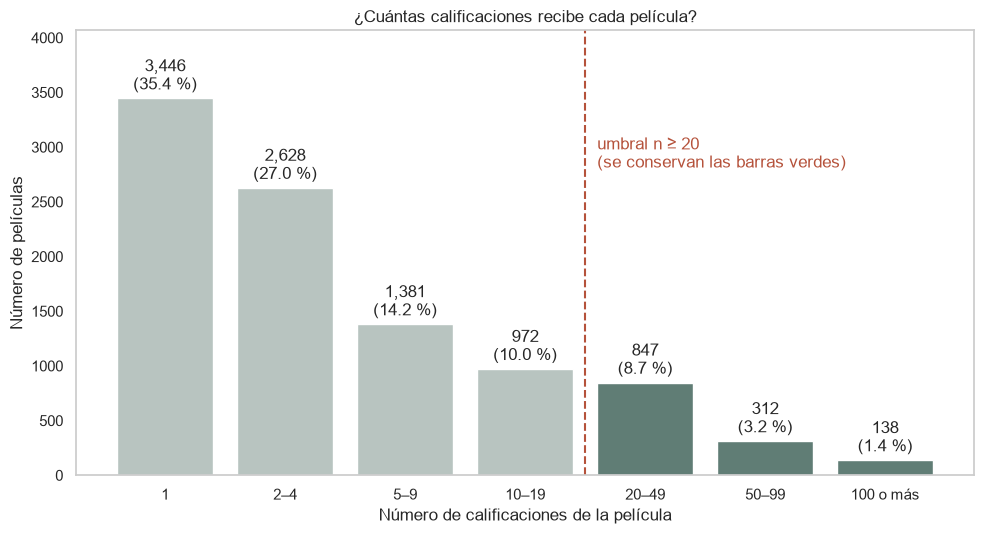

In [21]:
# gráfico de la distribución de ratings por película (muy asimétrica), por rangos
cortes = [0, 1, 4, 9, 19, 49, 99, np.inf]
etiquetas = ["1", "2–4", "5–9", "10–19", "20–49", "50–99", "100 o más"]

grupo = pd.cut(rev_por_pelicula, bins=cortes, labels=etiquetas)
tabla = grupo.value_counts().reindex(etiquetas)
pct = tabla / tabla.sum() * 100

# gris: películas con n < 20 (se descartan en la pregunta 1) · verde: n >= 20
colores = ["#B8C4C0"] * 4 + ["#607D75"] * 3

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.bar(etiquetas, tabla.to_numpy(), color=colores, edgecolor="white")
ax.bar_label(barras, labels=[f"{n:,}\n({p:.1f} %)" for n, p in zip(tabla, pct)], padding=3)

ax.axvline(3.5, color="#B5523B", linestyle="--")
ax.text(3.6, tabla.max() * 0.9, "umbral n ≥ 20\n(se conservan las barras verdes)",
        color="#B5523B", va="top")

ax.set(
    title="¿Cuántas calificaciones recibe cada película?",
    xlabel="Número de calificaciones de la película",
    ylabel="Número de películas",
    ylim=(0, tabla.max() * 1.18),
)
ax.grid(False)
plt.tight_layout()
rutas.guardar_figura(fig, "01_distribucion_ratings")
plt.show()

> **Interpretación**
> - *Qué muestra:* cuántas películas caen en cada rango de calificaciones recibidas. La mayoría de las películas casi no tiene calificaciones: el 62 % tiene 4 o menos y el 35 % (3,446 películas) tiene una sola. Solo 1,297 películas (13 %) llegan a 20 calificaciones, y 138 (1.4 %) llegan a 100 o más. Las barras verdes a la derecha de la línea punteada son las películas que sí cumplen el umbral n ≥ 20 (para el análisis de afinidades, pregunta 1).
> - *Por qué es relevante:* explica por qué el proyecto usa umbrales. Con una sola calificación la desviación estándar ni siquiera existe, y con pocas es puro ruido, así que la pregunta 1 trabaja solo con las películas de n ≥ 20. Para correlacionar películas entre usuarios (pregunta 2a) se necesitan más datos todavía, por eso se usa n ≥ 100. 
> - *Limitaciones:* los rangos son una decisión nuestra; otros cortes darían barras distintas, aunque la conclusión (muchas películas con muy pocas calificaciones) no cambia. Además, el número de calificaciones mide la popularidad **dentro de estos 610 usuarios**, no la popularidad real de la película. Y al agrupar se pierde el detalle dentro de cada rango, en particular la cola larga: la película más calificada tiene 329.

## 7. Bitácora de limpieza



In [22]:
# Variables que usa la celda de la bitácora
# 2) Títulos con dos movieId y usuarios que calificaron ambas versiones
titulos_limpios = movies_raw["title"].str.strip()
ids_por_titulo = movies_raw.groupby(titulos_limpios)["movieId"].nunique()
titulos_dup = ids_por_titulo[ids_por_titulo > 1].index

filas = []
for titulo in titulos_dup:
    ids = movies_raw.loc[titulos_limpios == titulo, "movieId"]
    por_usuario = ratings_raw[ratings_raw["movieId"].isin(ids)].groupby("userId")["movieId"].nunique()
    filas.append({"title": titulo,
                  "movieIds": ", ".join(ids),
                  "usuarios que calificaron ambas": int((por_usuario == 2).sum())})
resumen_dup = pd.DataFrame(filas)

# 3) Películas con IMAX
n_imax = int(movies_raw["genres"].str.split("|").apply(lambda g: "IMAX" in g).sum())

In [23]:
# Cifras para la evidencia
casos_dup = int(resumen_dup["usuarios que calificaron ambas"].sum())
tipo_ids = ", ".join(f"{col}: {t}" for col, t in por_defecto[["userId", "movieId"]].dtypes.astype(str).items())

n_umbral = int((rev_por_pelicula >= 20).sum())
pct_umbral = ratings["movieId"].isin(rev_por_pelicula[rev_por_pelicula >= 20].index).mean() * 100

bitacora = pd.DataFrame([
    {
        "id": 1,
        "problema": "IDs leídos como número pueden aparecer como 'x.0'; ratings fuera del conjunto válido",
        "evidencia": f"Lectura por defecto de pandas ({tipo_ids}): con un vacío saldrían como '1.0'. rating: {len(valores_rating)} valores distintos, todos en {{0.5, ..., 5.0}}",
        "decision": "Leer userId y movieId como str desde read_csv; validar rating contra {0.5, ..., 5.0}",
        "consecuencia": "IDs sin 'x.0' y ningún rating fuera de escala; si apareciera uno, ratings_limpias detiene el proceso con un error",
    },
    {
        "id": 2,
        "problema": "Títulos duplicados con movieId distinto",
        "evidencia": f"{len(titulos_dup)} títulos con dos movieId y géneros diferentes; {casos_dup} casos (usuario, título) en que el usuario calificó las dos versiones",
        "decision": "No fusionar; movieId sigue siendo la llave; mostrar título + movieId",
        "consecuencia": "Se conservan todas las calificaciones; si se fusionaran habría duplicados (userId, movieId) y se perderían ratings reales",
    },
    {
        "id": 3,
        "problema": "Películas con '(no genres listed)'",
        "evidencia": f"{sin_genero.sum()} películas ({sin_genero.mean() * 100:.2f}%) con {ratings_sin_genero.sum()} ratings ({ratings_sin_genero.mean() * 100:.2f}%)",
        "decision": "No imputar; se conservan en análisis por película y quedan fuera de los análisis por género",
        "consecuencia": "n_generos = 0 y todas sus columnas de género valen 0; impacto mínimo en los resultados",
    },
    {
        "id": 4,
        "problema": "IMAX en los datos pero no en el README (es un formato); 'Children's' vs 'Children'",
        "evidencia": f"{n_imax} películas con IMAX; el README lista \"Children's\" y los datos usan \"Children\"",
        "decision": "Excluir IMAX de los géneros y guardarlo como bandera es_imax; documentar la discrepancia",
        "consecuencia": f"movies queda con {len(contratos.GENEROS)} columnas de género 0/1 más es_imax",
    },
    {
        "id": 5,
        "problema": "Títulos con espacios sobrantes y sin año",
        "evidencia": f"{con_espacios.sum()} títulos con espacios; sin año: {sin_anio_sin_strip.sum()} si no se quitan los espacios, {sin_anio.sum()} si se quitan antes",
        "decision": "Quitar espacios antes de extraer el año; sin año queda <NA> y no se imputa",
        "consecuencia": f"anio se recupera en {sin_anio_sin_strip.sum() - sin_anio.sum()} títulos; {movies['anio'].isna().sum()} películas quedan con anio <NA>",
    },
    {
        "id": 6,
        "problema": "Estadísticos por película poco confiables con pocos ratings",
        "evidencia": f"Mediana de {rev_por_pelicula.median():.0f} ratings por película; {(rev_por_pelicula == 1).sum():,} películas con un solo rating; con n >= 20 quedan {n_umbral:,} películas y {pct_umbral:.0f}% de los ratings",
        "decision": "Umbral n >= 20 con análisis de sensibilidad (10, 20, 50); se desarrolla en el notebook 02",
        "consecuencia": "Medias y desviaciones más confiables a cambio de dejar fuera a las películas poco calificadas",
    },
])

rutas.guardar_tabla(bitacora, "bitacora_limpieza")

for _, fila in bitacora.iterrows():
    print(f"Decisión {fila['id']}: {fila['problema']}")
    print(f"  Evidencia:    {fila['evidencia']}")
    print(f"  Decisión:     {fila['decision']}")
    print(f"  Consecuencia: {fila['consecuencia']}")
    print()

Decisión 1: IDs leídos como número pueden aparecer como 'x.0'; ratings fuera del conjunto válido
  Evidencia:    Lectura por defecto de pandas (userId: int64, movieId: int64): con un vacío saldrían como '1.0'. rating: 10 valores distintos, todos en {0.5, ..., 5.0}
  Decisión:     Leer userId y movieId como str desde read_csv; validar rating contra {0.5, ..., 5.0}
  Consecuencia: IDs sin 'x.0' y ningún rating fuera de escala; si apareciera uno, ratings_limpias detiene el proceso con un error

Decisión 2: Títulos duplicados con movieId distinto
  Evidencia:    5 títulos con dos movieId y géneros diferentes; 4 casos (usuario, título) en que el usuario calificó las dos versiones
  Decisión:     No fusionar; movieId sigue siendo la llave; mostrar título + movieId
  Consecuencia: Se conservan todas las calificaciones; si se fusionaran habría duplicados (userId, movieId) y se perderían ratings reales

Decisión 3: Películas con '(no genres listed)'
  Evidencia:    34 películas (0.35%) con 47 r

## 8. Resumen

- Los datos están limpios en lo esencial: sin valores vacíos, con llaves válidas, ratings dentro de {0.5, …, 5.0} y sin ratings de películas inexistentes. Hay 18 películas sin ningún rating.
- Se tomaron 6 decisiones de limpieza (tipos, títulos duplicados, películas sin género, IMAX y año de estreno), todas registradas en la bitácora, más el umbral de ratings (decisión 6) que desarrolla el notebook 02.
- Se descartó fusionar títulos duplicados e imputar géneros para no perder ni inventar información.
- La distribución de ratings por película es muy asimétrica (mediana 3, máximo 329), por lo que las preguntas siguientes aplican un umbral mínimo de ratings.
- Los usuarios son una muestra autoseleccionada y los 10 más activos suman cerca del 16 % de los ratings; los resultados son descriptivos y no se generalizan.